# Практическая работа №2 "Создание конкуртной нейронной сети"

**Цель работы:** изучить топологию и алгоритм функционирования конкурентной нейронной сети.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

# ============================================
# 1. Исходные образы 6x6 (Вариант 29: *, /, +, =, #)
# ============================================

STAR = np.array([
    [0, 0, 1, 1, 0, 0],
    [1, 0, 1, 1, 0, 1],
    [0, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 0],
    [1, 0, 1, 1, 0, 1],
    [0, 0, 1, 1, 0, 0]
], dtype=float)

SLASH = np.array([
    [0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [1, 0, 0, 0, 0, 0]
], dtype=float)

PLUS = np.array([
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0]
], dtype=float)

EQUAL = np.array([
    [0, 0, 0, 0, 0, 0],
    [1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0]
], dtype=float)

HASH = np.array([
    [0, 1, 0, 0, 1, 0],
    [1, 1, 1, 1, 1, 1],
    [0, 1, 0, 0, 1, 0],
    [0, 1, 0, 0, 1, 0],
    [1, 1, 1, 1, 1, 1],
    [0, 1, 0, 0, 1, 0]
], dtype=float)

base_images = {
    "*": STAR,
    "/": SLASH,
    "+": PLUS,
    "=": EQUAL,
    "#": HASH
}


In [2]:
# ============================================
# 2. Вспомогательные функции
# ============================================

def to_vector(img):
    return img.T.reshape(-1).astype(float)

def normalize_vector(x):
    norm = np.linalg.norm(x)
    return x / norm if norm != 0 else x

def add_noise(img, flips):
    noisy = img.copy().reshape(-1)
    # Защита от случая, когда flips больше размера вектора
    idx = np.random.choice(len(noisy), size=flips, replace=False)
    noisy[idx] = 1 - noisy[idx]
    return noisy.reshape(img.shape)

def show_images(images_dict, title):
    fig, axes = plt.subplots(1, len(images_dict), figsize=(14, 3))
    # Если изображений всего 1, axes не будет массивом
    fig.suptitle(title, fontsize=14)
    for ax, (name, img) in zip(axes, images_dict.items()):
        ax.imshow(img, cmap="gray_r")
        ax.set_title(name)
        ax.axis("off")
    plt.show()


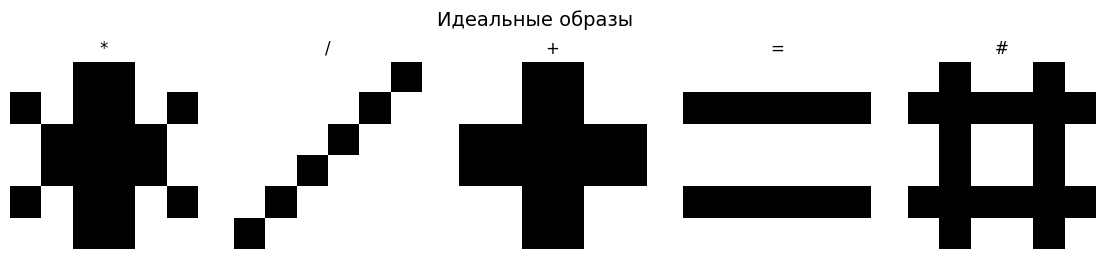

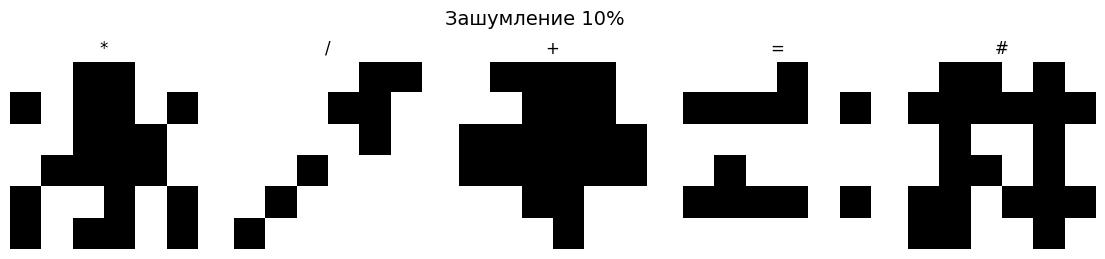

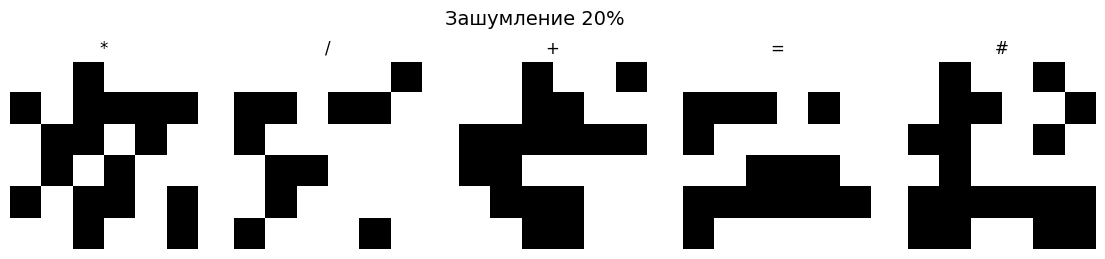

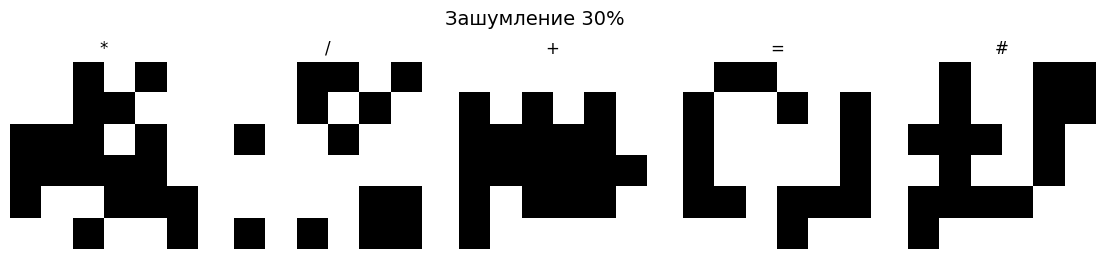

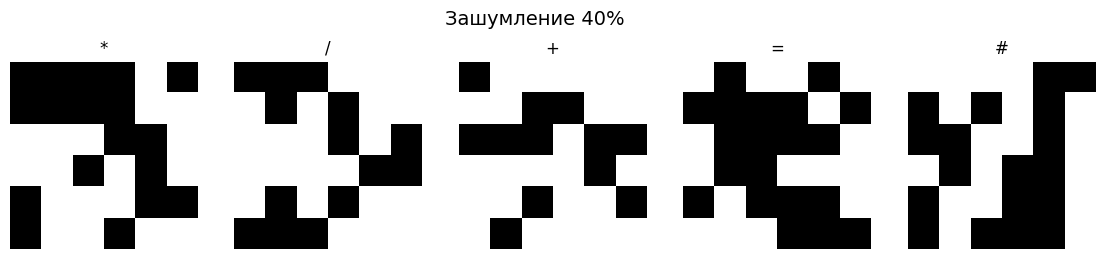

In [3]:
# ============================================
# 3. Создание зашумленных образов
# ============================================

noise_levels = {
    "0%": 0,
    "10%": 4,
    "20%": 7,
    "30%": 11,
    "40%": 14
}

all_images = {}
for noise_name, flips in noise_levels.items():
    all_images[noise_name] = {}
    for label, img in base_images.items():
        if flips == 0:
            all_images[noise_name][label] = img.copy()
        else:
            all_images[noise_name][label] = add_noise(img, flips)

show_images(base_images, "Идеальные образы")
show_images(all_images["10%"], "Зашумление 10%")
show_images(all_images["20%"], "Зашумление 20%")
show_images(all_images["30%"], "Зашумление 30%")
show_images(all_images["40%"], "Зашумление 40%")


In [4]:
# ============================================
# 4. Обучающая выборка (нормированные векторы)
# ============================================

labels = list(base_images.keys())
X_train = np.array([normalize_vector(to_vector(base_images[l])) for l in labels])


In [5]:
# ============================================
# 5. Обучение конкурентной сети
# ============================================

def train_competitive_network(X, m=5, h=0.05, epochs=30, seed=42):
    np.random.seed(seed)
    n = X.shape[1]  # Размерность входного вектора (36)

    # Инициализация весов случайными значениями от -1 до 1 и нормировка
    W = np.random.rand(n, m) * 2 - 1
    for j in range(m):
        W[:, j] = normalize_vector(W[:, j])

    # Фактор "совести" (частота побед)
    f = np.ones(m)

    for _ in range(epochs):
        for x in X:
            # Критерий KRIT_j = f_j * ||X - W_j||
            krit = np.array([np.linalg.norm(x - W[:, j]) * f[j] for j in range(m)])

            # Нейрон-победитель: минимальный критерий
            winner = int(np.argmin(krit))

            # Увеличение счетчика побед
            f[winner] += 1

            # Коррекция весов победителя (правило Кохонена) и нормировка
            W[:, winner] = W[:, winner] + h * (x - W[:, winner])
            W[:, winner] = normalize_vector(W[:, winner])

    return W, f


In [6]:
# ============================================
# 6. Классификация образов
# ============================================

def predict_cluster(x, W, f):
    x = normalize_vector(x)
    krit = np.array([np.linalg.norm(x - W[:, j]) * f[j] for j in range(W.shape[1])])
    return int(np.argmin(krit)) + 1  # Номер кластера (с 1)

def evaluate_network(all_images, W, f):
    levels = ["0%", "10%", "20%", "30%", "40%"]
    result = np.zeros((len(labels), len(levels)), dtype=int)
    for i, label in enumerate(labels):
        for j, level in enumerate(levels):
            x = to_vector(all_images[level][label])
            result[i, j] = predict_cluster(x, W, f)
    return result


In [7]:
# ============================================
# 7. Эксперимент 1: m = 5, h = 0.05
# ============================================

print("Обучение сети (m=5, h=0.05)...")
W7, f7 = train_competitive_network(X_train, m=5, h=0.05, epochs=30, seed=42)
REZ7 = evaluate_network(all_images, W7, f7)

print("\nРезультат для m = 5, h = 0.05")
print("Строки: " + ", ".join(labels))
print("Столбцы: 0%, 10%, 20%, 30%, 40%")
print(REZ7)


Обучение сети (m=5, h=0.05)...

Результат для m = 5, h = 0.05
Строки: *, /, +, =, #
Столбцы: 0%, 10%, 20%, 30%, 40%
[[5 5 5 2 5]
 [1 1 1 3 4]
 [2 2 2 5 2]
 [3 3 3 3 4]
 [4 4 4 4 4]]


In [8]:
# ============================================
# 8. Эксперимент 2: m = 4, h = 0.05
# ============================================

print("Обучение сети (m=4, h=0.05)...")
W8, f8 = train_competitive_network(X_train, m=4, h=0.05, epochs=30, seed=42)
REZ8 = evaluate_network(all_images, W8, f8)

print("\nРезультат для m = 4, h = 0.05")
print("Строки: " + ", ".join(labels))
print("Столбцы: 0%, 10%, 20%, 30%, 40%")
print(REZ8)


Обучение сети (m=4, h=0.05)...

Результат для m = 4, h = 0.05
Строки: *, /, +, =, #
Столбцы: 0%, 10%, 20%, 30%, 40%
[[3 1 1 1 1]
 [2 2 1 2 1]
 [3 1 1 1 1]
 [4 4 4 1 1]
 [1 1 1 1 1]]


In [9]:
# ============================================
# 9. Эксперимент 3: m = 3, h = 0.05
# ============================================

print("Обучение сети (m=3, h=0.05)...")
W9, f9 = train_competitive_network(X_train, m=3, h=0.05, epochs=30, seed=42)
REZ9 = evaluate_network(all_images, W9, f9)

print("\nРезультат для m = 3, h = 0.05")
print("Строки: " + ", ".join(labels))
print("Столбцы: 0%, 10%, 20%, 30%, 40%")
print(REZ9)


Обучение сети (m=3, h=0.05)...

Результат для m = 3, h = 0.05
Строки: *, /, +, =, #
Столбцы: 0%, 10%, 20%, 30%, 40%
[[2 2 2 2 3]
 [3 3 3 3 3]
 [2 2 2 3 3]
 [1 1 3 3 3]
 [1 1 3 3 3]]


In [10]:
# ============================================
# 10. Эксперимент 4: m = 5, h = 0.01
# ============================================

print("Обучение сети (m=5, h=0.01)...")
W10, f10 = train_competitive_network(X_train, m=5, h=0.01, epochs=30, seed=42)
REZ10 = evaluate_network(all_images, W10, f10)

print("\nРезультат для m = 5, h = 0.01")
print("Строки: " + ", ".join(labels))
print("Столбцы: 0%, 10%, 20%, 30%, 40%")
print(REZ10)


Обучение сети (m=5, h=0.01)...

Результат для m = 5, h = 0.01
Строки: *, /, +, =, #
Столбцы: 0%, 10%, 20%, 30%, 40%
[[5 5 3 3 5]
 [4 1 1 3 4]
 [2 2 4 5 2]
 [3 3 3 3 4]
 [1 1 1 1 3]]


In [11]:
# ============================================
# 11. Эксперимент 5: m = 5, h = 0.1
# ============================================

print("Обучение сети (m=5, h=0.1)...")
W11, f11 = train_competitive_network(X_train, m=5, h=0.1, epochs=30, seed=42)
REZ11 = evaluate_network(all_images, W11, f11)

print("\nРезультат для m = 5, h = 0.1")
print("Строки: " + ", ".join(labels))
print("Столбцы: 0%, 10%, 20%, 30%, 40%")
print(REZ11)


Обучение сети (m=5, h=0.1)...

Результат для m = 5, h = 0.1
Строки: *, /, +, =, #
Столбцы: 0%, 10%, 20%, 30%, 40%
[[5 5 5 2 5]
 [1 1 1 1 2]
 [2 2 2 2 2]
 [3 3 3 3 4]
 [4 4 4 4 4]]


**Вывод:**
1. Чем больше m, тем лучше разделяются образы. При m = 5 каждый из пяти образов попал в свой кластер, и при шуме до 20 % сеть распознаёт их правильно.
2. Чем меньше m, тем сильнее объединение образов. При m = 4 символы * и + попали в один кластер, а при m = 3 * с +, = с #. Ошибок при этом больше: 12 при m = 4 и 9 при m = 3, против 5 при m = 5.

**Малое h (0.01)**: веса меняются медленно, за 30 эпох сеть не успевает стабилизироваться. Ошибок 9.

**Среднее h (0.05)**: сеть быстро адаптируется, ошибок 5.

**Большое h (0.1)**: веса меняются сильнее, и сеть лучше распознаёт зашумлённые образы. Ошибок только 3, и символы + и # распознаются правильно при всех уровнях шума.

Наилучший результат получен при m = 5 и h = 0.1. При шуме 30–40 % ошибки появляются при любых параметрах, так как изменяется до 14 пикселей из 36.

##Контрольные вопросы

1.В чём заключается смысл самообучения нейронной сети?

**Самообучение** — это процесс, при котором нейронная сеть адаптируется к входным данным, выявляя внутренние зависимости и закономерности без использования размеченных данных и учителя.

2.Как выполняется обучение конкурентной нейронной сети?
Обучение происходит по следующему алгоритму:
* инициализация весов: векторы весов каждого нейрона инициализируются случайными значениями и нормируются;
* подача входного вектора: на вход сети подаётся нормированный вектор X;
* вычисление критерия для каждого нейрона: KRIT_j = f_j · ‖X − W_j‖, где f_j — число побед нейрона (фактор «совести»);
* определение победителя: нейрон с минимальным значением критерия;
* коррекция весов победителя по правилу Кохонена: W_j(t+1) = W_j(t) + h · (X − W_j(t)), где h — скорость обучения, затем нормировка;
* обновление счётчика побед: f_j = f_j + 1;
* повторение шагов для всех образцов в течение нескольких эпох до стабилизации кластеризации.

3.Каким образом определяется нейрон-победитель в конкурентной нейронной сети?

**Нейрон-победитель** — это нейрон, для которого критерий KRIT_j минимален. Это нейрон, вектор весов которого ближе всего к входному вектору с учётом того, сколько раз он уже побеждал. После этого веса победителя корректируются так, чтобы приблизиться к входному вектору, и он лучше распознаёт похожие образы при последующих подачах.

4.Где используются самоорганизующиеся нейронные сети?
* кластеризация данных;
* выделение признаков;
* сжатие представления данных.

5.Каковы основные достоинства и недостатки конкурентной нейронной сети?

**Достоинства:** обучение без учителя; устойчивость к шуму на небольших уровнях; результаты легко визуализировать и анализировать.

**Недостатки:** случайная инициализация может приводить к тому, что часть нейронов никогда не становится победителем (частотный фактор это частично решает); фиксированное число кластеров m нужно задавать заранее; чувствительность к выбору h и числа эпох.